# Path patching — figures + tables

Results of `scripts/diff/path_patch_eval.py` (job lists `job_list/diff_eval/path_patch_32b*.json`): multi-predicate
`a'b'c -> c` (SRC) / `a'b'd -> d` (DST), I3 = goal-250 heads read SRC's window k/v from ` =` on, I1 off, I2 = restore
`<|im_end|> .. {var}` from p_res `a'b'e`. Writes `notebooks/Figures/path_patch/*.{pdf,png}` and `tables.md`.
Readout-shift = share of ALL instances (paper convention, `readout_shift_rate`).

In [1]:
import os, sys, json, glob
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
sys.path.append("../..")
from src.utils import env_utils
import figstyle as F; F.set_style()

# task span of the runs: "list+gap__cppnote-sys" = task list + its closing `\n` (C++ note in the system prompt;
# reruns 2026-10-26/27, V 1/2/4) | "list" = task list only (old runs, V 1/2/4/6)
SPAN = "list+gap__cppnote-sys"
GROUP = "path_patch" if SPAN == "list" else "path_patch_listgap"   # keep the old-span figures intact
MODEL = "Qwen2.5-Coder-32B-Instruct"
ROOT = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "diff", MODEL, "path_patch")
HEADS = f"__span-{SPAN}__a1__th-goal_250__gh-goal_250__ro-goal_250"
DTS = ["int", "str", "list[int]", "list[str]"]
DT_DIR = {"int": "int", "str": "str", "list[int]": "list_int", "list[str]": "list_str"}
LANGS = ["python-python", "python-cpp", "cpp-python", "cpp-cpp"]
LANG_LBL = {"python-python": "py$\\to$py", "python-cpp": "py$\\to$cpp", "cpp-python": "cpp$\\to$py", "cpp-cpp": "cpp$\\to$cpp"}
LANG_MD = {"python-python": "py→py", "python-cpp": "py→cpp", "cpp-python": "cpp→py", "cpp-cpp": "cpp→cpp"}
VS = [1, 2, 4, 6] if SPAN == "list" else [1, 2, 4]
I2_COLOR = {False: F.OKABE_ITO[0], True: F.OKABE_ITO[1]}          # I2 off = blue, I2 on (p_res) = vermillion
I2_LBL = {False: "I2 off", True: "I2 on (p$_{res}$)"}
LANG_COLOR = dict(zip(LANGS, [F.OKABE_ITO[i] for i in (0, 1, 2, 3)]))


def run_dir(i2, v=1, window="span"):
    return os.path.join(ROOT, f"I1-off__I2-{'on-res' if i2 else 'off'}__I3-on{'' if v == 1 else f'-V{v}'}"
                              f"__win-{'span' if window == 'span' else 'span+prog'}{HEADS}")


def records(i2, v=1, window="span", dts=DTS, langs=LANGS):
    out = []
    for dt in dts:
        for lang in langs:
            fp = os.path.join(run_dir(i2, v, window), f"{DT_DIR[dt]}__{lang}", "results.json")
            out += [dict(r, _dt=dt, _lang=lang) for r in json.load(open(fp))]
    return out


def stats(R):
    c = [r["causal"]["triggered"] for r in R if r.get("causal")]
    ro = [r["readout"]["shifted"] for r in R if r.get("readout")]
    val = [r["readout"]["valid"] for r in R if r.get("readout")]
    e = [x["shifted_to_res"] for x in (r.get("readout_res") for r in R) if x]
    return dict(n=len(R), causal=np.mean(c), readout=np.mean(ro), valid=np.mean(val),
                to_e=(np.mean(e) if e else None))


for i2 in (False, True):
    for v in VS:
        for w in (["span", "span+progress"] if v == 1 else ["span"]):
            assert os.path.isdir(run_dir(i2, v, w)), run_dir(i2, v, w)
print("all run dirs present")

all run dirs present


## Aggregates

In [2]:
POOL = {(i2, v): stats(records(i2, v)) for i2 in (False, True) for v in VS}
SPROG = {i2: stats(records(i2, 1, "span+progress")) for i2 in (False, True)}
BYLANG = {(i2, v, l): stats(records(i2, v, langs=[l])) for i2 in (False, True) for v in VS for l in LANGS}
for k, s in POOL.items():
    print(k, {a: (round(b, 3) if isinstance(b, float) else b) for a, b in s.items()})
print("span+progress", {k: (round(s["causal"], 3), round(s["readout"], 3)) for k, s in SPROG.items()})

(False, 1) {'n': 512, 'causal': np.float64(0.721), 'readout': np.float64(0.67), 'valid': np.float64(0.957), 'to_e': None}
(False, 2) {'n': 512, 'causal': np.float64(0.867), 'readout': np.float64(0.832), 'valid': np.float64(0.957), 'to_e': None}
(False, 4) {'n': 512, 'causal': np.float64(0.936), 'readout': np.float64(0.9), 'valid': np.float64(0.957), 'to_e': None}
(True, 1) {'n': 512, 'causal': np.float64(0.842), 'readout': np.float64(0.73), 'valid': np.float64(0.957), 'to_e': np.float64(0.182)}
(True, 2) {'n': 512, 'causal': np.float64(0.938), 'readout': np.float64(0.898), 'valid': np.float64(0.957), 'to_e': np.float64(0.043)}
(True, 4) {'n': 512, 'causal': np.float64(0.973), 'readout': np.float64(0.922), 'valid': np.float64(0.957), 'to_e': np.float64(0.008)}
span+progress {False: (np.float64(0.99), np.float64(0.98)), True: (np.float64(0.992), np.float64(0.979))}


## Figure 1 · V-boost trend (pooled over 4 directions × 4 datatypes, n = 512 per point)

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/path_patch_listgap/vboost_trend.pdf


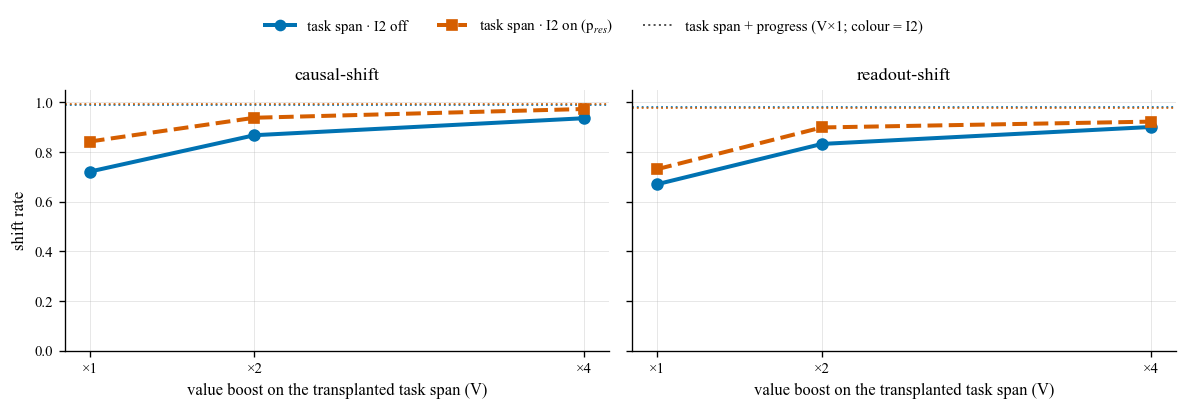

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, metric, title in zip(axes, ("causal", "readout"), ("causal-shift", "readout-shift")):
    for i2, ls, mk in ((False, "-", "o"), (True, "--", "s")):
        ax.plot(VS, [POOL[(i2, v)][metric] for v in VS], ls, marker=mk, color=I2_COLOR[i2], lw=2.4, ms=6.5)
        ax.axhline(SPROG[i2][metric], color=I2_COLOR[i2], lw=1.1, ls=":", alpha=0.9)
    ax.set_xticks(VS); ax.set_xticklabels([f"×{v}" for v in VS])
    ax.set_xlabel("value boost on the transplanted task span (V)"); ax.set_ylim(0, 1.05)
    ax.set_title(title); ax.grid(alpha=0.3)
axes[0].set_ylabel("shift rate")
hs = [Line2D([], [], color=I2_COLOR[False], ls="-", marker="o", lw=2.4, label="task span · I2 off"),
      Line2D([], [], color=I2_COLOR[True], ls="--", marker="s", lw=2.4, label="task span · I2 on (p$_{res}$)"),
      Line2D([], [], color="#555555", ls=":", lw=1.2, label="task span + progress (V×1; colour = I2)")]
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.legend(handles=hs, loc="lower center", bbox_to_anchor=(0.5, 0.9), ncol=3, frameon=False)
print("saved", F.save_fig(fig, GROUP, "vboost_trend")); plt.show()

## Figure 2 · V-boost trend per language direction (n = 128 per point)

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/path_patch_listgap/vboost_by_direction.pdf


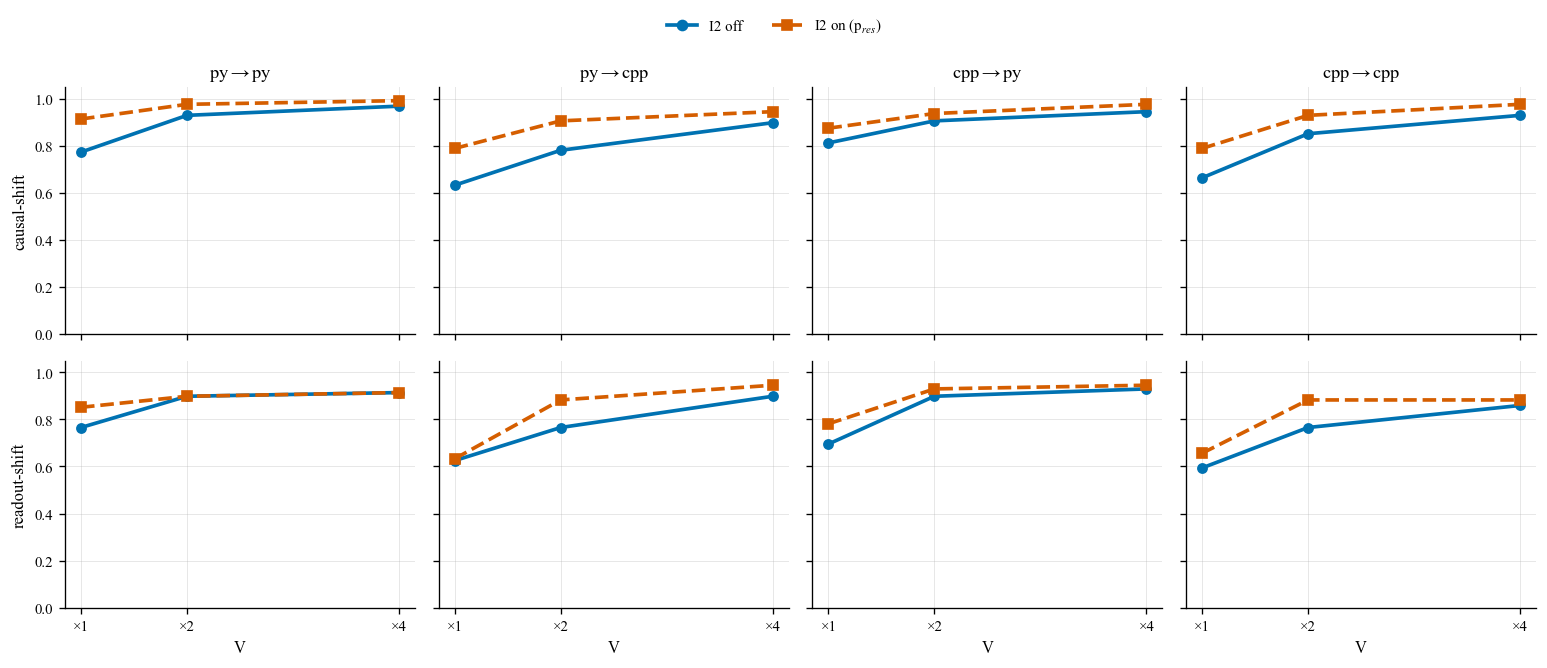

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharey=True, sharex=True)
for j, l in enumerate(LANGS):
    for i, (metric, name) in enumerate((("causal", "causal-shift"), ("readout", "readout-shift"))):
        ax = axes[i, j]
        for i2, ls, mk in ((False, "-", "o"), (True, "--", "s")):
            ax.plot(VS, [BYLANG[(i2, v, l)][metric] for v in VS], ls, marker=mk, color=I2_COLOR[i2], lw=2.2, ms=5.5)
        ax.set_ylim(0, 1.05); ax.grid(alpha=0.3); ax.set_xticks(VS); ax.set_xticklabels([f"×{v}" for v in VS])
        if i == 0: ax.set_title(LANG_LBL[l])
        if j == 0: ax.set_ylabel(name)
        if i == 1: ax.set_xlabel("V")
hs = [Line2D([], [], color=I2_COLOR[False], ls="-", marker="o", lw=2.2, label="I2 off"),
      Line2D([], [], color=I2_COLOR[True], ls="--", marker="s", lw=2.2, label="I2 on (p$_{res}$)")]
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.legend(handles=hs, loc="lower center", bbox_to_anchor=(0.5, 0.93), ncol=2, frameon=False)
print("saved", F.save_fig(fig, GROUP, "vboost_by_direction")); plt.show()

## Figure 3 · base grid (V×1): task span vs task span + progress, I2 off / on

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/path_patch_listgap/base_grid_bars.pdf


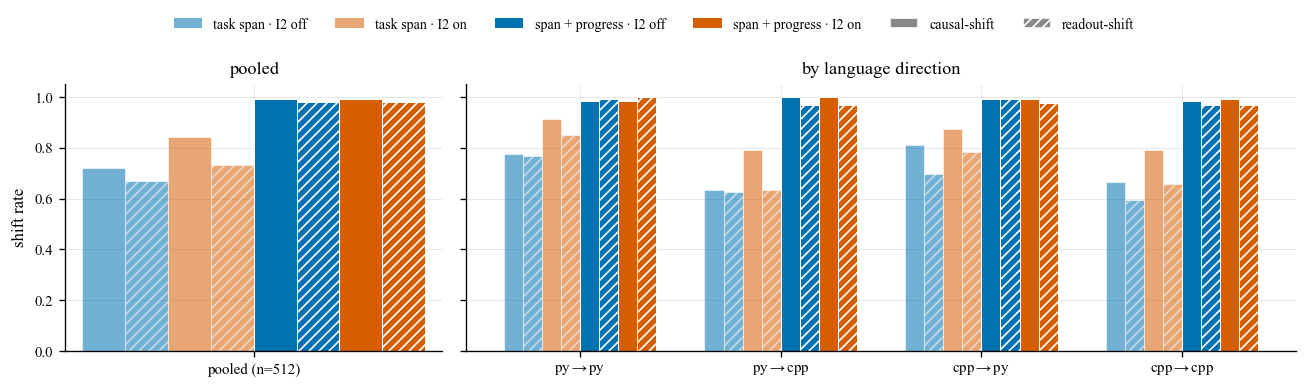

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True, gridspec_kw=dict(width_ratios=[1, 2.2]))
w = 0.19
def bars(ax, groups, getter, labels):
    x = np.arange(len(groups))
    for k, (i2, win) in enumerate(((False, "span"), (True, "span"), (False, "span+progress"), (True, "span+progress"))):
        off = (k - 1.5) * w
        c = [getter(g, i2, win)["causal"] for g in groups]; r = [getter(g, i2, win)["readout"] for g in groups]
        col = I2_COLOR[i2]; alpha = 0.55 if win == "span" else 1.0
        ax.bar(x + off - w / 4, c, w / 2, alpha=alpha, **F.metric_kw("causal", col))
        ax.bar(x + off + w / 4, r, w / 2, alpha=alpha, **F.metric_kw("readout", col))
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3)
def g_pool(g, i2, win): return POOL[(i2, 1)] if win == "span" else SPROG[i2]
def g_lang(l, i2, win): return BYLANG[(i2, 1, l)] if win == "span" else stats(records(i2, 1, "span+progress", langs=[l]))
bars(axes[0], ["all"], g_pool, ["pooled (n=512)"]); axes[0].set_ylabel("shift rate"); axes[0].set_title("pooled")
bars(axes[1], LANGS, g_lang, [LANG_LBL[l] for l in LANGS]); axes[1].set_title("by language direction")
hs = [Patch(facecolor=I2_COLOR[False], alpha=0.55, label="task span · I2 off"),
      Patch(facecolor=I2_COLOR[True], alpha=0.55, label="task span · I2 on"),
      Patch(facecolor=I2_COLOR[False], label="span + progress · I2 off"),
      Patch(facecolor=I2_COLOR[True], label="span + progress · I2 on"),
      Patch(facecolor="#888888", edgecolor="white", label="causal-shift"),
      Patch(facecolor="#888888", edgecolor="white", hatch=F.HATCH, label="readout-shift")]
fig.tight_layout(rect=(0, 0, 1, 0.86))
fig.legend(handles=hs, loc="lower center", bbox_to_anchor=(0.5, 0.86), ncol=6, frameon=False, fontsize=8.5)
print("saved", F.save_fig(fig, GROUP, "base_grid_bars")); plt.show()

## Figure 4 · readout drift to p_res's frontier e (I2 on), by direction

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/path_patch_listgap/vboost_readout_to_e.pdf


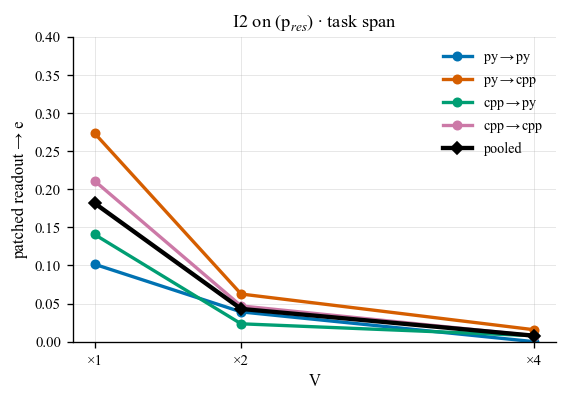

In [6]:
fig, ax = plt.subplots(figsize=(5.2, 3.3))
for l in LANGS:
    ax.plot(VS, [BYLANG[(True, v, l)]["to_e"] for v in VS], "-", marker="o", color=LANG_COLOR[l], lw=2, ms=5, label=LANG_LBL[l])
ax.plot(VS, [POOL[(True, v)]["to_e"] for v in VS], "-", color="#000000", lw=2.6, marker="D", ms=5, label="pooled")
ax.set_xticks(VS); ax.set_xticklabels([f"×{v}" for v in VS]); ax.set_ylim(0, 0.4); ax.grid(alpha=0.3)
ax.set_xlabel("V"); ax.set_ylabel("patched readout → e"); ax.set_title("I2 on (p$_{res}$) · task span")
ax.legend(frameon=False, fontsize=8.5, ncol=1, loc="upper right")
print("saved", F.save_fig(fig, GROUP, "vboost_readout_to_e")); plt.show()

## Tables → `notebooks/Figures/path_patch/tables.md`

In [7]:
def f2(x): return "—" if x is None else f"{x:.2f}"
L = []
L.append("### T1 · aggregated trend (pooled, n = 512 per cell)\n")
L.append("| V | I2 off · causal | I2 off · readout | I2 on · causal | I2 on · readout | I2 on · readout → e |")
L.append("|---|---|---|---|---|---|")
for v in VS:
    a, b = POOL[(False, v)], POOL[(True, v)]
    L.append(f"| ×{v} | {f2(a['causal'])} | {f2(a['readout'])} | {f2(b['causal'])} | {f2(b['readout'])} | {f2(b['to_e'])} |")
a, b = SPROG[False], SPROG[True]
L.append(f"| span + progress (×1) | {f2(a['causal'])} | {f2(a['readout'])} | {f2(b['causal'])} | {f2(b['readout'])} | {f2(b['to_e'])} |")
L.append("")
L.append("### T2 · trend by language direction (n = 128 per cell) — causal / readout\n")
L.append("| direction | I2 | " + " | ".join(f"×{v}" for v in VS) + " | span + progress |")
L.append("|---|---|" + "---|" * (len(VS) + 1))
for l in LANGS:
    for i2 in (False, True):
        sp = stats(records(i2, 1, "span+progress", langs=[l]))
        L.append(f"| {LANG_MD[l]} | {'on' if i2 else 'off'} | " + " | ".join(
            f"{f2(BYLANG[(i2, v, l)]['causal'])} / {f2(BYLANG[(i2, v, l)]['readout'])}" for v in VS)
            + f" | {f2(sp['causal'])} / {f2(sp['readout'])} |")
L.append("")
L.append("### T3 · full grids per config (n = 32 per cell) — causal / readout (clean-readout validity in brackets)\n")
def grid(i2, v, win, title):
    L.append(f"**{title}**\n")
    L.append("| datatype | " + " | ".join(LANG_MD[l] for l in LANGS) + " | all |")
    L.append("|---|" + "---|" * (len(LANGS) + 1))
    for dt in DTS + ["all"]:
        cells = []
        for l in LANGS + ["all"]:
            s = stats(records(i2, v, win, dts=DTS if dt == "all" else [dt], langs=LANGS if l == "all" else [l]))
            cells.append(f"{f2(s['causal'])} / {f2(s['readout'])}" + (f" · e {f2(s['to_e'])}" if i2 and s["to_e"] is not None else "")
                         + f" [{f2(s['valid'])}]")
        L.append(f"| {dt} | " + " | ".join(cells) + " |")
    L.append("")
for i2 in (False, True):
    for v in VS:
        grid(i2, v, "span", f"task span · I2 {'on (p_res)' if i2 else 'off'} · V×{v}")
for i2 in (False, True):
    grid(i2, 1, "span+progress", f"task span + progress · I2 {'on (p_res)' if i2 else 'off'} · V×1")
out = os.path.join(F.FIG_ROOT, GROUP, "tables.md")
open(out, "w").write("\n".join(L))
print("wrote", out, f"({len(L)} lines)")

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/path_patch_listgap/tables.md (93 lines)


## Per-I2 figures (by direction / by datatype) and tables

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/path_patch_listgap/vboost_i2off.pdf


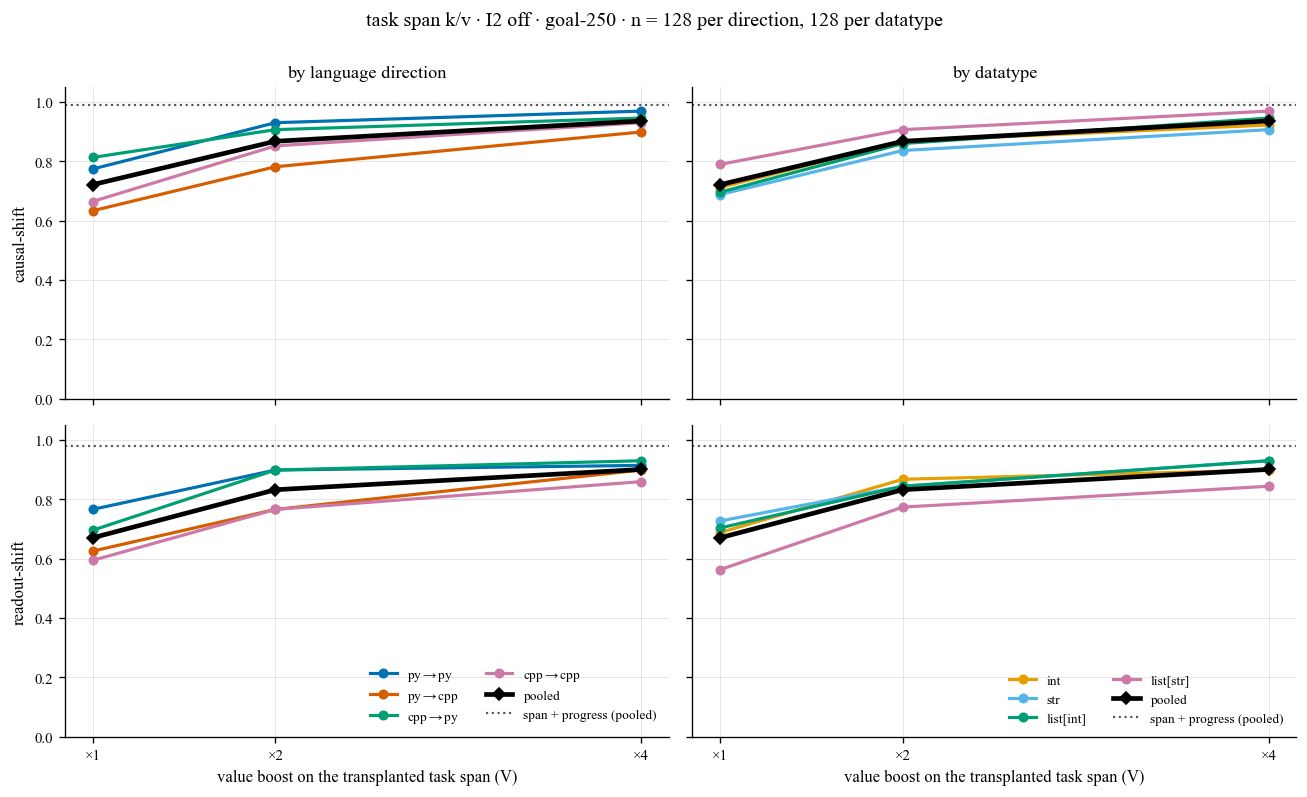

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/path_patch_listgap/vboost_i2on.pdf


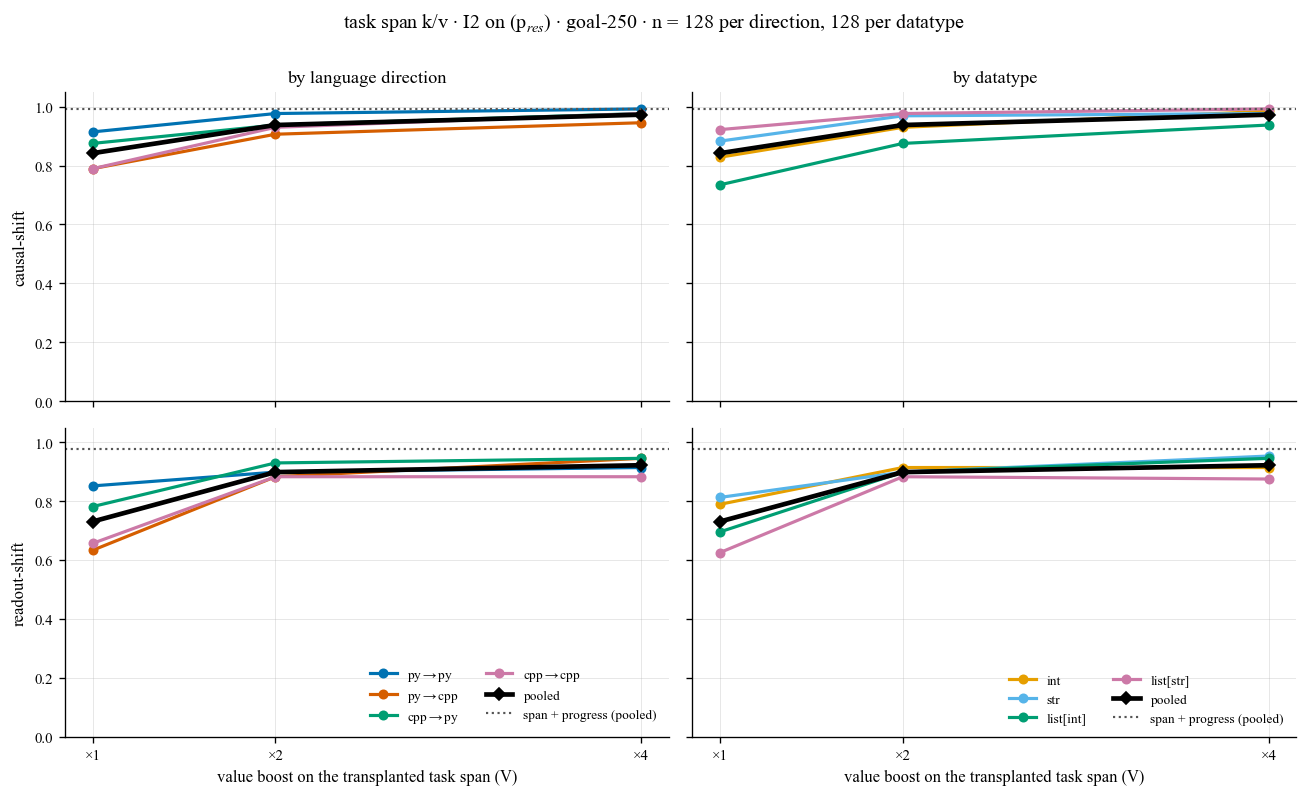

In [8]:
# ── per-I2 figures: causal / readout vs V, by language direction and by datatype ──
DT_COLOR = dict(zip(DTS, ["#E69F00", "#56B4E9", "#009E73", "#CC79A7"]))
DT_LBL = {d: d for d in DTS}
_cache = {}
def S(i2, v, window="span", dts=DTS, langs=LANGS):
    k = (i2, v, window, tuple(dts), tuple(langs))
    if k not in _cache:
        _cache[k] = stats(records(i2, v, window, dts=dts, langs=langs))
    return _cache[k]

for i2 in (False, True):
    fig, axes = plt.subplots(2, 2, figsize=(11, 6.6), sharey=True, sharex=True)
    for col, (cat, vals, lbl, colors) in enumerate((("lang", LANGS, LANG_LBL, LANG_COLOR), ("dt", DTS, DT_LBL, DT_COLOR))):
        for row, (metric, mname) in enumerate((("causal", "causal-shift"), ("readout", "readout-shift"))):
            ax = axes[row, col]
            for val in vals:
                kw = dict(langs=[val]) if cat == "lang" else dict(dts=[val])
                ax.plot(VS, [S(i2, v, **kw)[metric] for v in VS], "-", marker="o", color=colors[val], lw=1.9, ms=5,
                        label=lbl[val])
            ax.plot(VS, [S(i2, v)[metric] for v in VS], "-", color="#000000", lw=2.8, marker="D", ms=5, label="pooled")
            ax.axhline(S(i2, 1, "span+progress")[metric], color="#555555", ls=":", lw=1.3, label="span + progress (pooled)")
            ax.set_ylim(0, 1.05); ax.grid(alpha=0.3); ax.set_xticks(VS); ax.set_xticklabels([f"×{v}" for v in VS])
            if row == 0: ax.set_title("by language direction" if cat == "lang" else "by datatype")
            if col == 0: ax.set_ylabel(mname)
            if row == 1: ax.set_xlabel("value boost on the transplanted task span (V)")
            if row == 1: ax.legend(frameon=False, fontsize=8, loc="lower right", ncol=2)
    fig.suptitle(f"task span k/v · I2 {'on (p$_{res}$)' if i2 else 'off'} · goal-250 · n = 128 per direction, 128 per datatype",
                 y=1.0, fontsize=12)
    fig.tight_layout()
    print("saved", F.save_fig(fig, GROUP, f"vboost_i2{'on' if i2 else 'off'}")); plt.show()

In [9]:
# ── per-I2 tables -> tables_i2off.md / tables_i2on.md ──
def cell(s, e=False):
    return f"{f2(s['causal'])} / {f2(s['readout'])}" + (f" · e {f2(s['to_e'])}" if e and s["to_e"] is not None else "")

for i2 in (False, True):
    T = []
    rows = [(f"×{v}", dict(v=v, window="span")) for v in VS] + [("span + progress (×1)", dict(v=1, window="span+progress"))]
    T.append("Each cell: causal-shift / readout-shift" + (" · readout → e" if i2 else "") + ".\n")
    T.append("**Pooled and by language direction** (n = 512 pooled, 128 per direction)\n")
    T.append("| V | pooled | " + " | ".join(LANG_MD[l] for l in LANGS) + " |")
    T.append("|---|---|" + "---|" * len(LANGS))
    for name, kw in rows:
        T.append(f"| {name} | {cell(S(i2, kw['v'], kw['window']), i2)} | "
                 + " | ".join(cell(S(i2, kw["v"], kw["window"], langs=[l]), i2) for l in LANGS) + " |")
    T.append("")
    T.append("**By datatype** (n = 128 per datatype, pooled over directions)\n")
    T.append("| V | " + " | ".join(DTS) + " |")
    T.append("|---|" + "---|" * len(DTS))
    for name, kw in rows:
        T.append(f"| {name} | " + " | ".join(cell(S(i2, kw["v"], kw["window"], dts=[d]), i2) for d in DTS) + " |")
    T.append("")
    T.append("**Full grids** (datatype × direction, n = 32 per cell; clean-readout validity in brackets)\n")
    for name, kw in rows:
        T.append(f"*{name}*\n")
        T.append("| datatype | " + " | ".join(LANG_MD[l] for l in LANGS) + " | all |")
        T.append("|---|" + "---|" * (len(LANGS) + 1))
        for dt in DTS + ["all"]:
            cs = []
            for l in LANGS + ["all"]:
                s = S(i2, kw["v"], kw["window"], dts=DTS if dt == "all" else [dt], langs=LANGS if l == "all" else [l])
                cs.append(cell(s, i2) + f" [{f2(s['valid'])}]")
            T.append(f"| {dt} | " + " | ".join(cs) + " |")
        T.append("")
    out = os.path.join(F.FIG_ROOT, GROUP, f"tables_i2{'on' if i2 else 'off'}.md")
    open(out, "w").write("\n".join(T)); print("wrote", out, len(T), "lines")

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/path_patch_listgap/tables_i2off.md 54 lines
wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/path_patch_listgap/tables_i2on.md 54 lines
